# Figure 8 · Measurement robustness

**Question:** Does the observed-shape improvement survive reasonable measurement choices?

**Status:** completed legacy epoch-49 robustness analysis, validation only.
All 21 predeclared scenarios are shown. The main preview uses the **same global
intersection** of successful objects across all scenarios, alongside full-sample
measurement success fractions. It does not tune a measurement choice to maximize gain.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'

In [2]:
analysis = ROOT / 'runs/shape-robustness-best49'
assert read_json(analysis/'status.json')['complete']
report = read_json(analysis/'report.json')
protocol = read_json(analysis/'protocol.json')
assert protocol['split'] == 'validation'
SCENARIOS = list(protocol['scenarios'])
assert set(SCENARIOS) == set(report['scenarios'])
POPULATION = 'global_matched'
FIGSIZE = (8.5, 8.0)
labels = {
 'fixed_nominal':'Fixed moments: nominal', 'weight_sigma8':'Weight σ = 8', 'weight_sigma12':'Weight σ = 12',
 'aperture20':'Aperture radius = 20', 'aperture30':'Aperture radius = 30',
 'center_xplus2':'Center x +2 pixels', 'center_xminus2':'Center x −2 pixels',
 'center_yplus2':'Center y +2 pixels', 'center_yminus2':'Center y −2 pixels',
 'background_sr_plus':'SR background +0.1 RMS', 'background_sr_minus':'SR background −0.1 RMS',
 'background_jwst_plus':'JWST background +0.1 RMS', 'background_jwst_minus':'JWST background −0.1 RMS',
 'background_nisp_plus':'NISP background +0.1 RMS', 'background_nisp_minus':'NISP background −0.1 RMS',
 'hsm105':'Adaptive moments: crop 105', 'hsm155':'Adaptive moments: crop 155',
 'hsm105_guess15':'Adaptive moments: initial σ = 15',
 'input_noise_seed0':'Input noise: trial 1', 'input_noise_seed1':'Input noise: trial 2',
 'input_noise_seed2':'Input noise: trial 3'}
print('Shared objects across every scenario:', report['global_common_count'])
print('Background/noise perturbations:', protocol['background'], protocol['noise'])

Shared objects across every scenario: 1098
Background/noise perturbations: Measurement-only signed offsets ±0.1 times per-object outer sky RMS; not calibrated background uncertainty. NISP offsets affect only native/interpolated baseline measurements; SR/JWST offsets affect that image only. Add independent Gaussian noise of 0.25 times supplied NISP pixel RMS to valid input pixels, re-run SR and interpolation; three fixed seeds. A 6.25% variance increase under an independent-noise approximation; no JWST noise model.


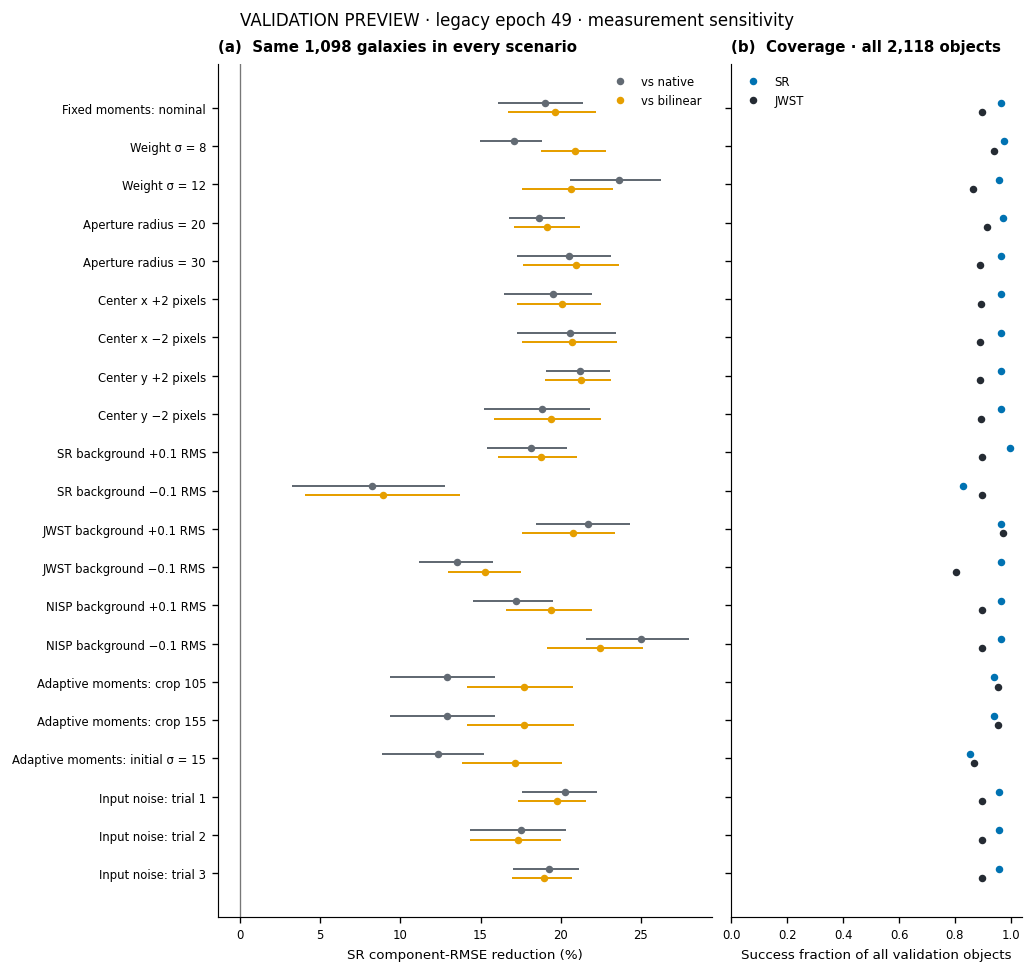

In [3]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={'width_ratios':[1.7, 1]},
                         layout='constrained', sharey=True)
y = np.arange(len(SCENARIOS))
for baseline, offset in [('native', -.12), ('bilinear', .12)]:
    gains, lower, upper = [], [], []
    for name in SCENARIOS:
        result = report['scenarios'][name][POPULATION]['methods'][baseline]['sr_comparison']
        gains.append(result['improvement_percent'])
        interval = result['ci95_percent'] or [np.nan, np.nan]
        lower.append(interval[0]); upper.append(interval[1])
    axes[0].hlines(y+offset, lower, upper, color=COLORS[baseline], lw=1.2)
    axes[0].plot(gains, y+offset, 'o', ms=3.5, color=COLORS[baseline], label='vs ' + baseline)
axes[0].axvline(0, color='#777777', lw=.8)
axes[0].set_yticks(y, [labels[name] for name in SCENARIOS])
axes[0].invert_yaxis()
axes[0].set_xlabel('SR component-RMSE reduction (%)')
axes[0].legend(frameon=False)
panel(axes[0], 'a', f"Same {report['global_common_count']:,} galaxies in every scenario")
for method, offset, color in [('sr', -.12, COLORS['legacy']), ('jwst', .12, COLORS['jwst'])]:
    fractions = [report['scenarios'][name]['all_objects']['success_counts'][method]/report['objects'] for name in SCENARIOS]
    axes[1].plot(fractions, y+offset, 'o', color=color, ms=3.5, label=method.upper())
axes[1].set(xlim=(0, 1.04), xlabel='Success fraction of all validation objects')
axes[1].legend(frameon=False)
panel(axes[1], 'b', f"Coverage · all {report['objects']:,} objects")
fig.suptitle('VALIDATION PREVIEW · legacy epoch 49 · measurement sensitivity', fontsize=10)
plt.show()

In [4]:
paths = export(fig, f'fig08_shape_robustness_{VERSION}', '08_shape_robustness.ipynb',
    [analysis/'report.json', analysis/'protocol.json'],
    dict(figsize=FIGSIZE, scenarios=SCENARIOS, population=POPULATION,
         common_objects=report['global_common_count']), status='legacy-only validation robustness preview')

Exported: fig08_shape_robustness_v01.pdf, fig08_shape_robustness_v01.svg, fig08_shape_robustness_v01.png


## Working caption and review choices

Sensitivity of observed-shape improvement to weight, aperture, centroid,
background, estimator and input-noise choices. The gain panel uses the identical
global-success population across all predeclared scenarios; the coverage panel
shows success fractions on all validation objects. Intervals are conditional
95% spatial-block percentiles. Sizes and center offsets are in target-grid pixels;
native NISP measurements use the corresponding angular region. Adaptive moments measure a different weighted shape,
so absolute errors should not be interpreted as the same estimator's target.

- This is likely an appendix-sized figure; a main-text summary can use a
  scientifically justified subset, retaining the complete suite here.
- Background shifts are stress amplitudes, not calibrated background errors.
- Input-noise trials add 0.25 times supplied pixel RMS; correlations are not modeled.
- Keep both estimator coverage and matched-population gains visible.
- A separate diffusion-variability panel should use completed full-run outputs,
  not the small pilot or a visually chosen seed.